In [1]:
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from juego_piedras_bt import juego_piedras, Color
from juego_piedras_pl import juego_piedras_pl
from util import time_algorithm

In [2]:
def generar_aleatorio(m):
    n = 2 * m
    valores = np.random.choice([0, 1, 2], size=(n, m), p=[0.35, 0.325, 0.325])
    return [[Color(int(celda)) for celda in fila] for fila in valores]

def generar_peor_caso(m):
    tablero = [[Color.VACIO] * m for _ in range(2 * m)]
    for j in range(m):
        tablero[2 * j][j] = Color.VERDE
        tablero[2 * j + 1][j] = Color.CELESTE
    return tablero

In [3]:
x = np.arange(2, 13)

def medir(algoritmo, generador, tamanios, runs):
    np.random.seed(12345)
    return time_algorithm(algoritmo, tamanios, lambda m: [generador(m)], runs_per_size=runs)

bt_aleatorio = medir(juego_piedras,    generar_aleatorio, x, runs=50)
bt_peor      = medir(juego_piedras,    generar_peor_caso, x, runs=10)
pl_aleatorio = medir(juego_piedras_pl, generar_aleatorio, x, runs=50)
pl_peor      = medir(juego_piedras_pl, generar_peor_caso, x, runs=10)

In [4]:
tabla = pd.DataFrame({
    "BT aleatorio": bt_aleatorio,
    "PL aleatorio": pl_aleatorio,
    "BT peor caso": bt_peor,
    "PL peor caso": pl_peor,
})
tabla.index.name = "Cantidad de columnas"
display(tabla)

,BT aleatorio,PL aleatorio,BT peor caso,PL peor caso
Cantidad de columnas,,,,
2,0.000017,0.003361,0.000023,0.003253
3,0.000042,0.003691,0.000070,0.003306
4,0.000087,0.004212,0.000251,0.003233
5,0.000188,0.004050,0.001061,0.003386
6,0.000179,0.004281,0.004405,0.003560
7,0.000234,0.004574,0.020017,0.003515
8,0.000141,0.004800,0.059932,0.003600
9,0.002015,0.005468,0.191617,0.003765
10,0.000189,0.005727,0.680363,0.003744


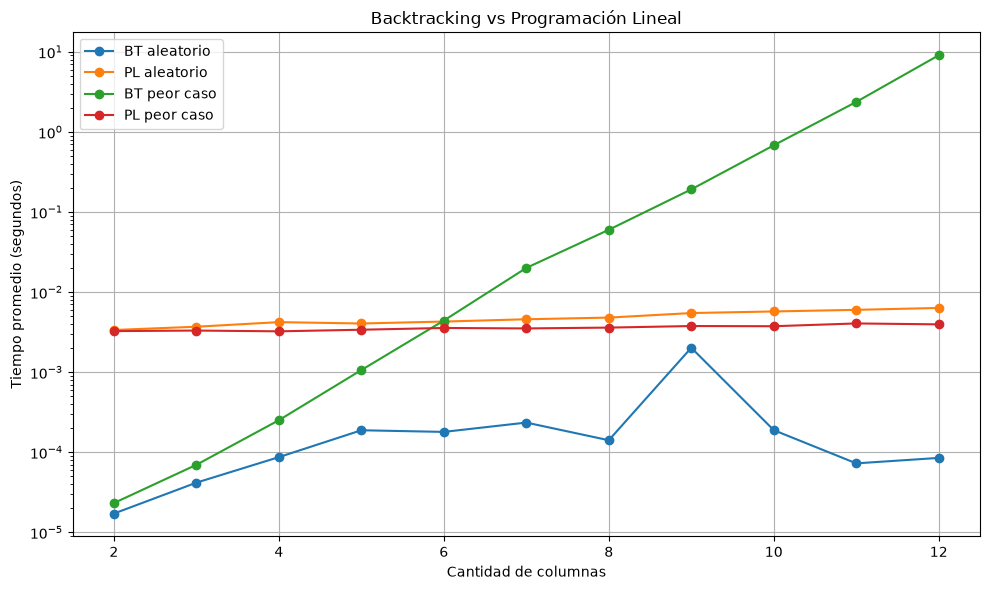

In [5]:
plt.figure(figsize=(10, 6))
for col in tabla.columns:
    plt.plot(x, tabla[col], marker="o", label=col)
plt.yscale("log")
plt.xlabel("Cantidad de columnas")
plt.ylabel("Tiempo promedio (segundos)")
plt.title("Backtracking vs Programación Lineal")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig("comparacion_bt_pl.png", dpi=300, bbox_inches="tight")
plt.show()